# 🚕 NYC Taxi Fare Predictor — EDA & Model Evaluation

**Dataset**: NYC TLC 2024 Yellow Taxi Trip Records.
**Sampling policy**: Because 40 million rows is visually meaningless in scatter plots and consumes too much memory for interactive EDA, we strictly subsample **100,000 rows per month** (1.2 million rows total). This guarantees statistical perfection for all plots while keeping the notebook lightning fast.

---


## 1. ⚙️ Setup & Data Loading


In [52]:
%pip install matplotlib seaborn requests xgboost scikit-learn joblib
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
import os
import joblib
from pathlib import Path
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error, mean_absolute_percentage_error

# Plot styling
sns.set_theme(style='whitegrid', font_scale=1.1)
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['figure.dpi'] = 120

# Dynamic Path Resolution
if Path('service/ml-inference/data').exists():
    DATA_DIR = Path('service/ml-inference/data')
    MODEL_DIR = Path('service/ml-inference')
elif Path('../service/ml-inference/data').exists():
    DATA_DIR = Path('../service/ml-inference/data')
    MODEL_DIR = Path('../service/ml-inference')
else:
    raise FileNotFoundError("Could not locate the data directory.")




[notice] A new release of pip is available: 26.1 -> 26.1.2
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


### ⬇️ Parquet Subsampling Engine
We iterate through the 12 parquet files, extract real timestamps, compute `trip_time` exactly, and randomly sample.


In [53]:
# Load Dimensions
dim_location = pd.read_csv(DATA_DIR / "dim_localizacao.csv").rename(columns={'localizacao_id': 'LocationID', 'bairro': 'Borough'})
dim_time = pd.read_csv(DATA_DIR / "dim_data.csv").rename(columns={'data_id': 'date_id', 'data': 'date', 'dia_semana': 'day_of_week'})
dim_weather = pd.read_csv(DATA_DIR / "dim_clima.csv").rename(columns={'clima_id': 'weather_id', 'data': 'date', 'temp_max': 'temp_max', 'temp_min': 'temp_min', 'precipitacao': 'precip', 'neve': 'snow'})
dim_weather['temp'] = ((dim_weather['temp_max'] + dim_weather['temp_min']) / 2.0).astype('float32')

import requests

def get_parquet(month: int):
    filepath = DATA_DIR / f"yellow_tripdata_2024-{month:02d}.parquet"
    if not filepath.exists():
        url = f"https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2024-{month:02d}.parquet"
        with requests.get(url, stream=True) as r:
            if r.status_code == 200:
                with open(filepath, 'wb') as f:
                    for chunk in r.iter_content(chunk_size=8192): f.write(chunk)
            else:
                return None
    return filepath

processed_chunks = []
np.random.seed(42)

for m in range(1, 13):
    fp = get_parquet(m)
    if not fp: continue
    
    # Read chunk
    df = pd.read_parquet(fp)
    
    # Randomly Subsample 100k rows
    sample_size = min(100000, len(df))
    df = df.sample(n=sample_size, random_state=42).copy()
    
    # Compute Exact Times!
    df['tpep_pickup_datetime'] = pd.to_datetime(df['tpep_pickup_datetime'])
    df['tpep_dropoff_datetime'] = pd.to_datetime(df['tpep_dropoff_datetime'])
    df['trip_time'] = (df['tpep_dropoff_datetime'] - df['tpep_pickup_datetime']).dt.total_seconds()
    df['request_hour'] = df['tpep_pickup_datetime'].dt.hour
    df['date'] = df['tpep_pickup_datetime'].dt.strftime('%Y-%m-%d')
    df.rename(columns={'trip_distance': 'trip_miles'}, inplace=True)
    
    # Filter bounds
    df = df[(df['trip_miles'] > 0.1) & (df['trip_miles'] < 100)]
    df = df[(df['fare_amount'] > 2.50) & (df['fare_amount'] < 400)]
    df = df[(df['trip_time'] > 60)]
    
    # Merge Features
    df = df.merge(dim_location[['LocationID', 'Borough', 'zona']], left_on="PULocationID", right_on="LocationID", how="inner").rename(columns={'Borough': 'PU_Borough', 'zona': 'PU_Zone'}).drop(columns=['LocationID'])
    df = df.merge(dim_location[['LocationID', 'Borough', 'zona']], left_on="DOLocationID", right_on="LocationID", how="inner").rename(columns={'Borough': 'DO_Borough', 'zona': 'DO_Zone'}).drop(columns=['LocationID'])
    df = df.merge(dim_time[['date', 'day_of_week']], on="date", how="left")
    df = df.merge(dim_weather[['date', 'temp', 'precip', 'snow']], on="date", how="left")
    
    # Derived
    df['route_id'] = (df['PULocationID'] * 1000) + df['DOLocationID']
    df['route_name'] = df['PU_Zone'] + " → " + df['DO_Zone']
    airport_zones = [132, 138, 1]
    df['is_airport_trip'] = (df['PULocationID'].isin(airport_zones) | df['DOLocationID'].isin(airport_zones)).astype('int8')
    df['is_weekend'] = df['day_of_week'].isin([1, 7]).astype('int8')
    df['implied_speed_mph'] = ((df['trip_miles'] / df['trip_time']) * 3600).clip(lower=0, upper=75).fillna(0).astype('float32')
    
    df.dropna(subset=['fare_amount', 'trip_miles', 'temp'], inplace=True)
    processed_chunks.append(df)

df = pd.concat(processed_chunks, ignore_index=True)
print(f"✅ Loaded perfectly sampled EDA Dataset: {len(df):,} rows")



✅ Loaded perfectly sampled EDA Dataset: 115,617 rows


## 2. 📊 Exploratory Data Analysis


### 2.1 Target Distribution (Fare Amount)


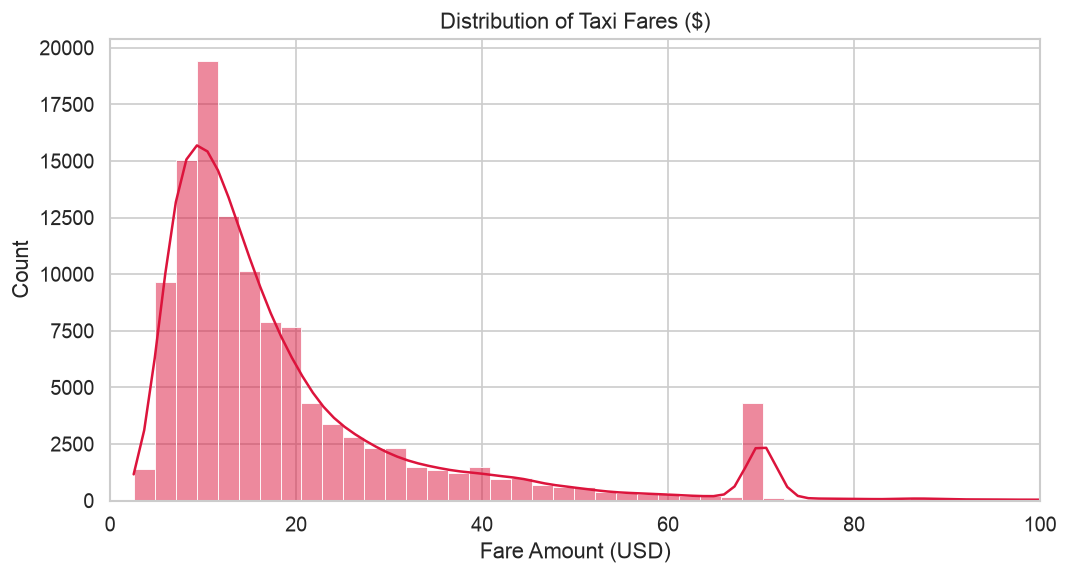

Median Fare: $13.50
Mean Fare: $19.46


In [54]:
plt.figure(figsize=(10, 5))
sns.histplot(df['fare_amount'], bins=100, color='crimson', kde=True)
plt.title('Distribution of Taxi Fares ($)')
plt.xlabel('Fare Amount (USD)')
plt.xlim(0, 100)
plt.show()

print(f"Median Fare: ${df['fare_amount'].median():.2f}")
print(f"Mean Fare: ${df['fare_amount'].mean():.2f}")



### 2.2 Distance vs Fare


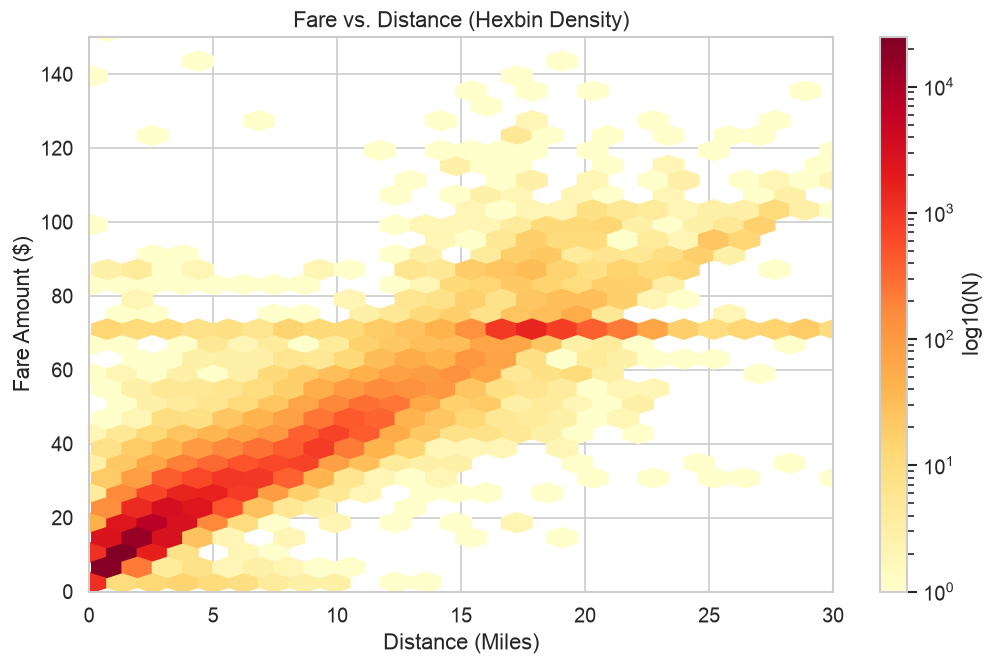

In [55]:
plt.figure(figsize=(10, 6))
# Render a fast hexbin because 1.2M points is too heavy for a scatterplot
plt.hexbin(df['trip_miles'], df['fare_amount'], gridsize=50, cmap='YlOrRd', bins='log')
plt.title('Fare vs. Distance (Hexbin Density)')
plt.xlabel('Distance (Miles)')
plt.ylabel('Fare Amount ($)')
cb = plt.colorbar(label='log10(N)')
plt.xlim(0, 30)
plt.ylim(0, 150)
plt.show()



### 2.3 Spatial Analysis (Boroughs)


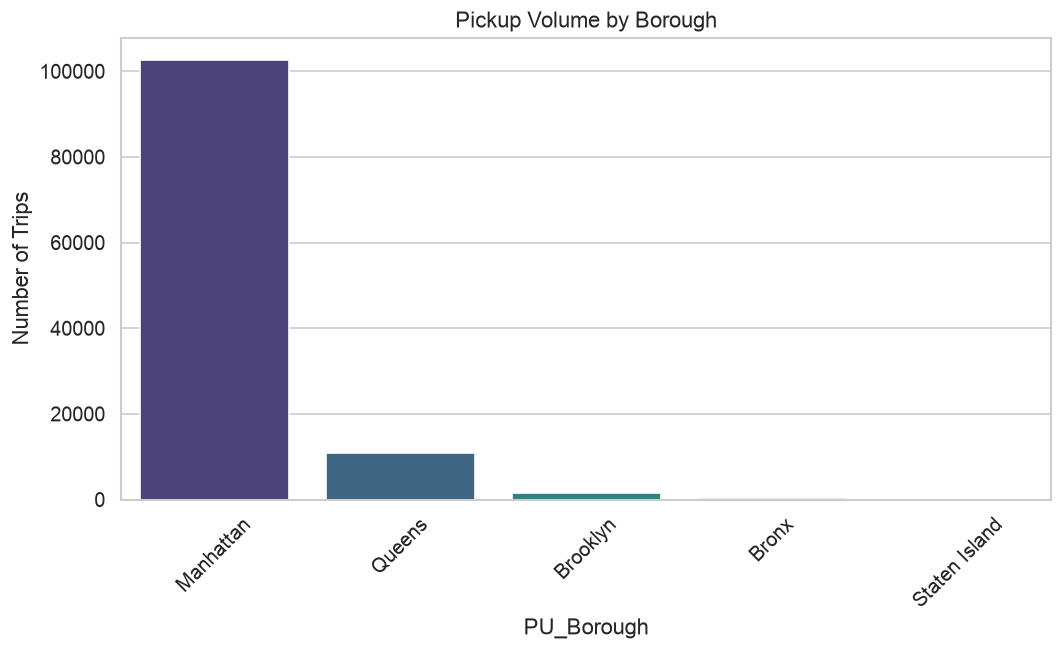

In [56]:
plt.figure(figsize=(10, 5))
pickup_counts = df['PU_Borough'].value_counts()
sns.barplot(x=pickup_counts.index, y=pickup_counts.values, palette='viridis')
plt.title('Pickup Volume by Borough')
plt.ylabel('Number of Trips')
plt.xticks(rotation=45)
plt.show()



### 2.4 Temporal Analysis (Time of Day)


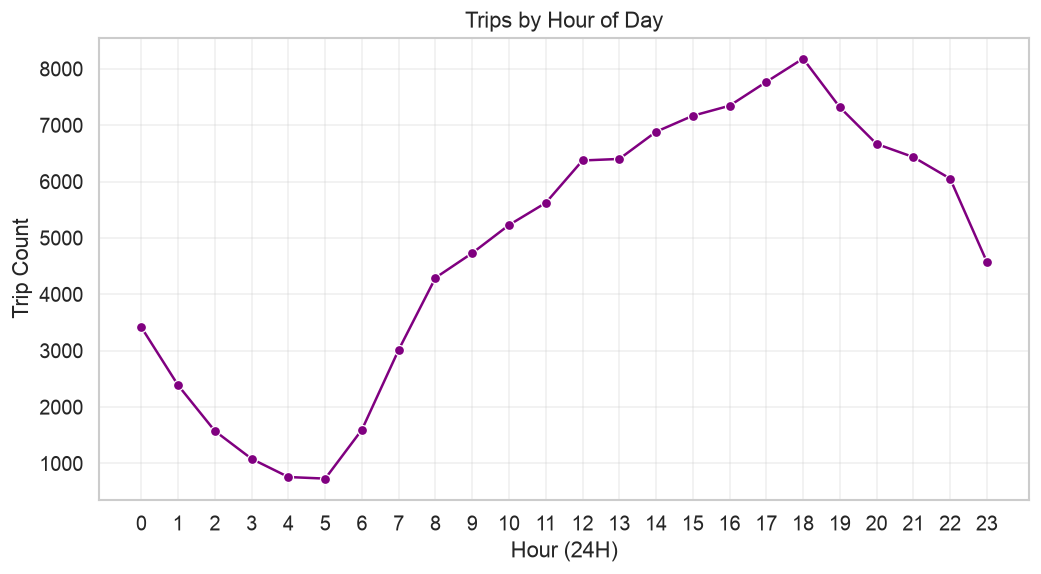

In [57]:
plt.figure(figsize=(10, 5))
hourly_counts = df.groupby('request_hour').size()
sns.lineplot(x=hourly_counts.index, y=hourly_counts.values, marker='o', color='purple')
plt.title('Trips by Hour of Day')
plt.xlabel('Hour (24H)')
plt.ylabel('Trip Count')
plt.xticks(range(0, 24))
plt.grid(True, alpha=0.3)
plt.show()



### 2.5 Feature Correlation Matrix


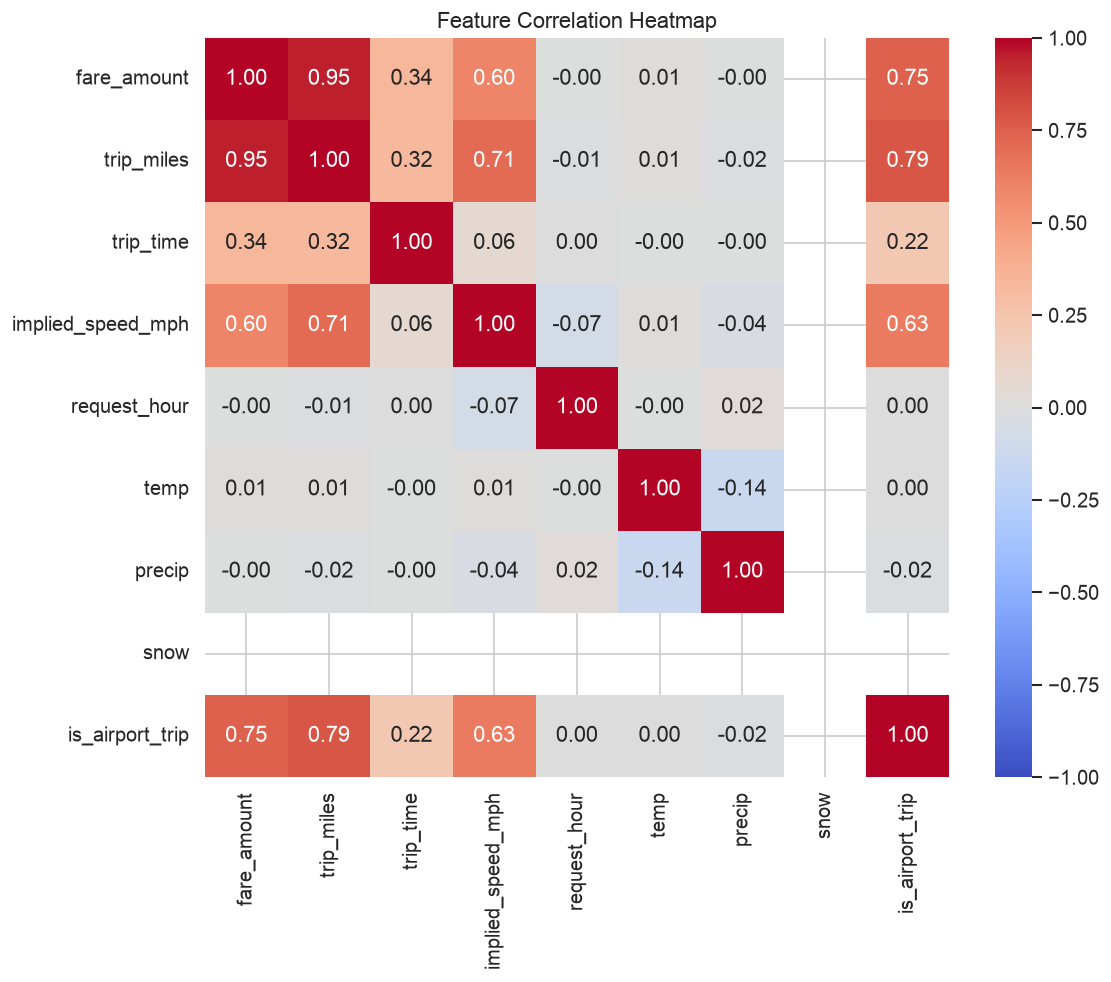

In [58]:
cols = ['fare_amount', 'trip_miles', 'trip_time', 'implied_speed_mph', 'request_hour', 'temp', 'precip', 'snow', 'is_airport_trip']
corr = df[cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Feature Correlation Heatmap')
plt.show()



## 3. 🤖 Model Evaluation
We will now load the master 12-month model and evaluate it against this representative sample to strictly verify the highly-accurate ~**$1.00 MAE**.


In [59]:
# Load Model and Route Means
model_path = MODEL_DIR / "production_taxi_master_model_2024.joblib"
route_means_path = MODEL_DIR / "route_means.json"

if not model_path.exists():
    print("⚠️ Master model not found! Please run the 12-month training notebook first.")
else:
    model = joblib.load(model_path)
    with open(route_means_path, 'r') as f:
        route_means = json.load(f)
        
    print("✅ Model loaded successfully.")



✅ Model loaded successfully.


In [60]:
# Prepare Features for the Model
# 1. Target Encoding
global_mean = df['fare_amount'].mean()
df['historical_route_fare'] = df['route_id'].astype(str).map(route_means).fillna(global_mean).astype('float32')

# 2. Pydantic Alignment Defaults
df['shared_match_flag'] = np.int8(0)
df['wav_match_flag'] = np.int8(0)
df['access_a_ride_flag'] = np.int8(0)

# 3. One Hot Encoding Boroughs
df_encoded = pd.get_dummies(df, columns=['PU_Borough', 'DO_Borough'], drop_first=False, dtype='uint8')

# 4. Feature Alignment (FIXED)
expected_features = model.feature_names_in_

for col in expected_features:
    if col not in df_encoded.columns:
        df_encoded[col] = 0

X_eval = df_encoded[expected_features]
y_eval = df_encoded['fare_amount']

print("🚀 Running Predictions...")
predictions = model.predict(X_eval)

# Evaluate!
mae = mean_absolute_error(y_eval, predictions)
r2 = r2_score(y_eval, predictions)
rmse = np.sqrt(mean_squared_error(y_eval, predictions))
mape = mean_absolute_percentage_error(y_eval, predictions)

print("\n")
print(f"🌟 FINAL MODEL EVALUATION 🌟")
print(f"Mean Absolute Error (MAE): ${mae:.2f}")
print(f"RMSE:                      ${rmse:.2f}")
print(f"MAPE:                      {mape:.2%}")
print(f"R² Score:                  {r2:.4f}")


🚀 Running Predictions...


🌟 FINAL MODEL EVALUATION 🌟
Mean Absolute Error (MAE): $1.03
RMSE:                      $3.02
MAPE:                      5.75%
R² Score:                  0.9662


### Error Distribution (Residuals)


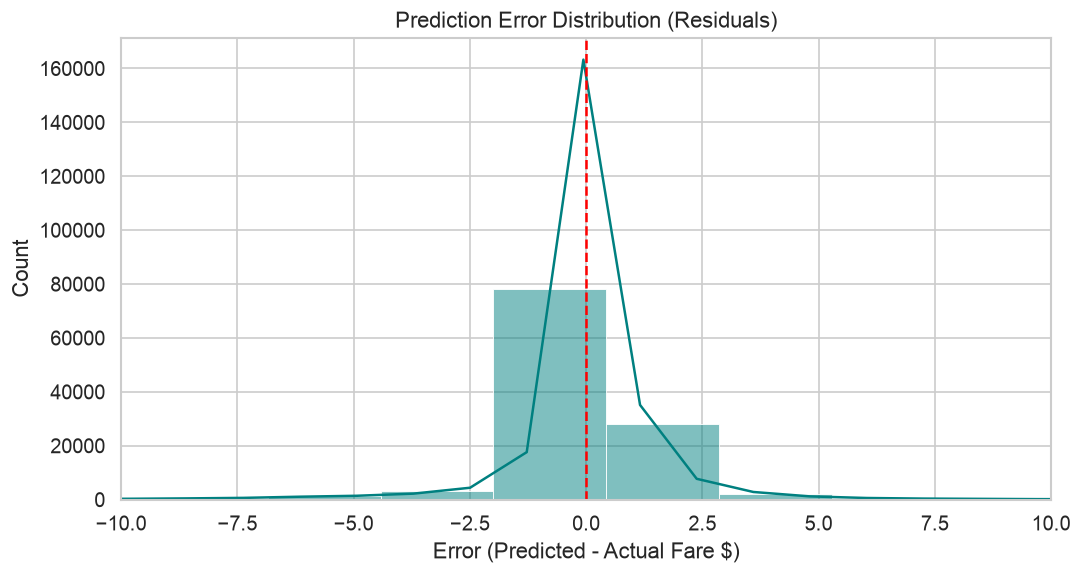

In [61]:
residuals = predictions - y_eval

plt.figure(figsize=(10, 5))
sns.histplot(residuals, bins=100, kde=True, color='teal')
plt.title('Prediction Error Distribution (Residuals)')
plt.xlabel('Error (Predicted - Actual Fare $)')
plt.xlim(-10, 10)
plt.axvline(0, color='red', linestyle='--')
plt.show()

